# NarrativeCast — Baseline Feasibility Study
**Đề tài:** *Predicting Emerging Narratives in Social Media Using Temporal Semantic Representations*  
**Tài liệu quy chiếu:** [`docs/problem_specification.md`](../docs/problem_specification.md) & [`docs/related_work.md`](../docs/related_work.md)  
**Phạm vi nghiên cứu chính:** Bài đăng Reddit thuộc cộng đồng Technology (`r/technology`) trong bộ dữ liệu MADOC.  

---

## 📌 1. Bối cảnh & Mục tiêu Nghiên cứu Khả thi

Theo đặc tả bài toán trong [docs/problem_specification.md](../docs/problem_specification.md):
- **Đối tượng nghiên cứu:** Các *narratives* trên mạng xã hội. Một narrative là một mạch diễn giải, quan điểm hoặc thông điệp chung được thể hiện qua nhiều bài đăng liên quan. **Narrative không đồng nghĩa với Topic**: một topic (ví dụ: *AI Governance*) có thể bao gồm nhiều narrative đối lập (ví dụ: *AI Regulation Stifles Innovation* vs. *AI Safety Demands Urgent Guardrails*).
- **Mục tiêu cốt lõi:** Đánh giá tính khả thi kỹ thuật của việc xây dựng các mô hình baseline nhằm dự đoán narratives nào sẽ trở nên nổi bật trong các cửa sổ tương lai $h \in \{3, 7, 14\}$ ngày, dựa trên nội dung và lịch sử hoạt động.
- **Nhiệm vụ cụ thể của notebook này:**
  1. **Xác định các trường dữ liệu cần thiết** từ bộ dữ liệu MADOC phục vụ cho baseline và lộ trình mô hình chính.
  2. **Thiết kế cơ chế cửa sổ thời gian (Temporal Windowing)** không gây rò rỉ dữ liệu (Data Leakage).
  3. **Đo lường mức độ nổi bật (Prominence Score $P(n, W_t)$)** và xác định mục tiêu đánh giá $y_{n,t,h}$ theo chuẩn của `problem_specification.md`.
  4. **Cài đặt & Đánh giá các mô hình Baseline:** *Popularity Baseline*, *Persistence Baseline*, và *Growth Momentum Baseline* trên nhiều đường chân trời dự báo $h = 3, 7, 14$ ngày (trả lời **RQ2**).
  5. **Cung cấp bằng chứng khả thi & Ghi rõ phần chưa làm được** theo khung 3 khối chức năng trong `related_work.md`.
  6. **Đóng góp đoạn văn bản cho Phần 5 — Experimental Setup** của bài báo nghiên cứu (~0.1 cột).

## 2. Xác Định Các Trường Dữ Liệu Cần Thiết (Data Schema Analysis)

Dựa trên [docs/dataset_card.md](../docs/dataset_card.md) và [docs/problem_specification.md](../docs/problem_specification.md), bảng dưới đây phân loại và đánh giá tính cần thiết của 13 trường dữ liệu chuẩn hóa của MADOC:

| Tên trường (Field) | Kiểu dữ liệu | Nhóm vai trò | Bắt buộc cho Baseline? | Đánh giá kỹ thuật trong NarrativeCast |
| :--- | :--- | :--- | :---: | :--- |
| `publish_date` | Timestamp (UNIX) | **Trục thời gian** | **Bắt buộc** | Dùng để phân chia các lát cắt thời gian, xác định mốc dự đoán $t$, cửa sổ lịch sử $W_{\text{hist}} = [t-k, t]$ và cửa sổ tương lai $W_{\text{future}} = (t, t+h]$. |
| `content` | String (Text) | **Ngữ nghĩa văn bản** | **Bắt buộc** | Đầu vào nhận diện narrative, trích xuất từ khóa, vector biểu diễn (SBERT) và phân loại lập trường theo BERTopic [1]. |
| `post_id` | String | **Định danh bài viết** | **Bắt buộc** | Khóa duy nhất dùng để đếm số lượng bài đăng $N_{n,t}$ và tổng số bài đăng $N_t$ trong cửa sổ. |
| `community` | String / NA | **Lọc phạm vi dữ liệu** | **Bắt buộc** | Lọc chính xác cộng đồng công nghệ `r/technology` theo phạm vi nghiên cứu của đề tài. |
| `platform` | Enum | **Lọc nền tảng** | **Bắt buộc** | Lọc dữ liệu `reddit` theo quy định tại Mục 2 của `problem_specification.md`. |
| `interaction_type` | Enum (`POST`, `COMMENT`) | **Trọng số tương tác** | Khuyến nghị | Phân biệt bài mở đầu (`POST`) và thảo luận mở rộng (`COMMENT`). |
| `user_id` | String (Anonymized) | **Cấu trúc cộng đồng** | Khuyến nghị (Weng et al.) | Đo lường số người dùng duy nhất, phục vụ tính các chỉ số *adoption dominance* và *adoption entropy* [2]. |
| `parent_id` | String / NA | **Cấu trúc cascade** | Khuyến nghị (Weng et al.) | Xây dựng đồ thị tương tác phản hồi (reply network), đo lường độ phân nhánh thảo luận. |
| `parent_user_id` | String / NA | **Tương tác người dùng** | Tùy chọn | Xác định quan hệ phản hồi trực tiếp giữa người dùng trong đồ thị. |
| `sentiment_vader` | Float (-1.0 đến 1.0) | **Đặc trưng cảm xúc** | Mở rộng | Bổ trợ nhận diện khung lập trường (stance/framing) của narrative. |
| `strict_filter` | Binary (0 / 1) | **Bộ lọc chất lượng** | Khuyến nghị | Loại bỏ các bài đăng rác hoặc nằm ngoài tiêu chí nghiên cứu. |
| `url` | String | **Nguồn trích dẫn** | Tùy chọn | Phân tích nguồn báo chí công nghệ bên ngoài (Ars Technica, The Verge,...). |
| `language` | String (`en`) | **Kiểm soát ngôn ngữ** | Tiêu chuẩn | Đảm bảo tính nhất quán ngôn ngữ tiếng Anh. |

### 🎯 Hợp đồng dữ liệu tối thiểu (Minimum Viable Data Contract):
Để baseline hoạt động, tối thiểu cần: `publish_date`, `content`, `post_id`, `platform`, `community`.  
Để mở rộng sang mô hình dự báo chính (Weng et al. [2] + TFT [3]), cần bổ sung: `user_id`, `parent_id`, `interaction_type`, `sentiment_vader`.

## 3. Nạp Dữ liệu Mẫu Reddit r/technology (Data Ingestion)

Ta nạp bộ dữ liệu mẫu mô phỏng `data/sample/madoc_sample.parquet` gồm 5,000 bài đăng/bình luận trong 60 ngày liên tục tại Reddit `r/technology`.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF

# Cấu hình đồ họa trực quan
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.figsize'] = (11, 5)
plt.rcParams['figure.dpi'] = 110

sample_path = os.path.join("..", "data", "sample", "madoc_sample.parquet")

if not os.path.exists(sample_path):
    print(f"Warning: File {sample_path} not found. Running generator script...")
    sys.path.append(os.path.join("..", "scripts"))
    from generate_sample_data import generate_sample_data
    df = generate_sample_data(num_samples=5000)
    os.makedirs(os.path.dirname(sample_path), exist_ok=True)
    df.to_parquet(sample_path, index=False)
else:
    df = pd.read_parquet(sample_path)

df['datetime'] = pd.to_datetime(df['publish_date'], unit='s', utc=True)

print(f"✅ Đã nạp thành công {len(df):,} bản ghi từ: {sample_path}")
print(f"🌐 Nền tảng: {df['platform'].unique().tolist()} | Cộng đồng: {df['community'].unique().tolist()}")
print(f"📅 Khoảng thời gian: {df['datetime'].min().strftime('%Y-%m-%d')} đến {df['datetime'].max().strftime('%Y-%m-%d')} (Tổng cộng {(df['datetime'].max() - df['datetime'].min()).days} ngày)")
print(f"📊 Danh sách 6 Narratives được theo dõi:")
for n, count in df['ground_truth_narrative'].value_counts().items():
    print(f"   - {n}: {count:,} bài đăng")
df.head(3)

✅ Đã nạp thành công 5,000 bản ghi từ: ..\data\sample\madoc_sample.parquet
🌐 Nền tảng: ['reddit'] | Cộng đồng: ['technology']
📅 Khoảng thời gian: 2024-01-01 đến 2024-02-29 (Tổng cộng 59 ngày)
📊 Danh sách 6 Narratives được theo dõi:
   - AI_Regulation_Stifles_Innovation: 1,255 bài đăng
   - Open_Source_AI_Democratization: 1,058 bài đăng
   - AI_Safety_Demands_Urgent_Guardrails: 1,001 bài đăng
   - Big_Tech_Antitrust_Breakup: 796 bài đăng
   - Semiconductor_Foundry_Sovereignty: 602 bài đăng
   - Critical_Zero_Day_Infrastructure_Breach: 288 bài đăng


,post_id,publish_date,user_id,parent_id,parent_user_id,content,url,language,interaction_type,platform,community,sentiment_vader,strict_filter,topic,ground_truth_narrative,datetime
0,madoc_red_98894057c8e3,1704069879,usr_1a1657ff,NaN,NaN,[AI Governance] Proposed bureaucratic guardrai...,https://reddit.com/r/technology/comments/e0637c,en,POST,reddit,technology,-0.4589,0,AI Governance,AI_Regulation_Stifles_Innovation,2024-01-01 00:44:39+00:00
1,madoc_red_b7e67c942e83,1704070375,usr_e06d7be9,NaN,NaN,[Hardware & Supply Chain] Automakers and elect...,,en,POST,reddit,technology,-0.6171,0,Hardware & Supply Chain,Semiconductor_Foundry_Sovereignty,2024-01-01 00:52:55+00:00
2,madoc_red_8c1b85079569,1704068028,usr_a455ca48,NaN,NaN,[AI Governance] Uncontrolled deployment of dee...,,en,POST,reddit,technology,-0.2737,0,AI Governance,AI_Safety_Demands_Urgent_Guardrails,2024-01-01 00:13:48+00:00


## 4. Phân biệt Narrative và Topic (Narrative vs. Topic Demonstration)

Theo Mục 2 của `problem_specification.md`, **Narrative khác Topic**:
- **Topic** biểu thị chủ đề thảo luận chung (ví dụ: *AI Governance*).
- **Narrative** biểu thị mạch diễn giải hoặc quan điểm cụ thể (ví dụ: *AI Regulation Stifles Innovation* vs. *AI Safety Demands Urgent Guardrails*). Hai narrative này cùng thuộc một topic nhưng có thông điệp và động lực lan truyền hoàn toàn khác nhau.

Dưới đây, ta đối chiếu các bài đăng thuộc cùng topic *AI Governance* nhưng mang hai narrative đối lập:

In [2]:
ai_gov_df = df[df['topic'] == 'AI Governance']
print(f"📌 Tổng số bài thảo luận về Topic [AI Governance]: {len(ai_gov_df):,} bài")
print("\nĐối chiếu 2 Narratives đối lập trong cùng Topic:")
for narr in ["AI_Regulation_Stifles_Innovation", "AI_Safety_Demands_Urgent_Guardrails"]:
    sample_post = ai_gov_df[ai_gov_df['ground_truth_narrative'] == narr]['content'].iloc[0]
    print(f"\n➤ Narrative: [{narr}]")
    print(f"   Trích dẫn ví dụ: '{sample_post}'")

📌 Tổng số bài thảo luận về Topic [AI Governance]: 2,256 bài

Đối chiếu 2 Narratives đối lập trong cùng Topic:

➤ Narrative: [AI_Regulation_Stifles_Innovation]
   Trích dẫn ví dụ: '[AI Governance] Proposed bureaucratic guardrails on open-weight machine learning threaten independent open research. Discussion around stifle innovation.'

➤ Narrative: [AI_Safety_Demands_Urgent_Guardrails]
   Trích dẫn ví dụ: '[AI Governance] Uncontrolled deployment of deepfakes and automated social bots threatens democratic election integrity. Discussion around model audit.'


## 5. Thiết kế Cửa sổ Thời gian & Tính Điểm Nổi bật (Prominence Score)

### 5.1. Định nghĩa toán học về Mức độ nổi bật (Prominence Score):
Theo Mục 5.2 của `problem_specification.md`, mức độ nổi bật của narrative $n$ trong cửa sổ $W_t$ được định nghĩa là tỷ trọng thảo luận:
$$P(n, W_t) = \frac{N_{n,t}}{N_t}$$
Trong đó:
- $N_{n,t}$: Số lượng bài đăng hợp lệ thuộc narrative $n$ trong cửa sổ $W_t$.
- $N_t$: Tổng số bài đăng hợp lệ trong cửa sổ $W_t$.
- $P(n, W_t) \in [0, 1]$: Tỷ trọng bài đăng của narrative $n$.

### 5.2. Mục tiêu dự đoán (Prediction Target):
Theo Mục 5.3 của `problem_specification.md`, tại thời điểm dự đoán $t$, mô hình chỉ được sử dụng dữ liệu $\le t$. Với khoảng dự đoán tương lai $h \in \{3, 7, 14\}$ ngày, giá trị mục tiêu thực tế (ground truth) là:
$$y_{n,t,h} = P(n, (t, t+h])$$

In [3]:
def compute_prominence_matrix(df: pd.DataFrame, bin_days: int = 3) -> tuple[pd.DataFrame, pd.DataFrame, pd.DatetimeIndex]:
    """
    Tính ma trận Khối lượng (Volume N_{n,t}) và Mức độ nổi bật (Prominence P(n, W_t))
    cho từng narrative qua các time bins có độ dài bin_days.
    """
    df_sorted = df.copy().sort_values('datetime')
    min_time = df_sorted['datetime'].min().floor('D')
    max_time = df_sorted['datetime'].max().ceil('D')
    
    bin_edges = pd.date_range(start=min_time, end=max_time, freq=f'{bin_days}D', tz='UTC')
    df_sorted['bin_id'] = pd.cut(df_sorted['datetime'], bins=bin_edges, right=False, labels=range(len(bin_edges)-1))
    
    df_clean = df_sorted.dropna(subset=['bin_id']).copy()
    df_clean['bin_id'] = df_clean['bin_id'].astype(int)
    
    # 1. Ma trận Volume N_{n,t}
    volume_matrix = pd.pivot_table(
        df_clean,
        index='bin_id',
        columns='ground_truth_narrative',
        values='post_id',
        aggfunc='count',
        fill_value=0
    )
    
    # 2. Tổng số bài đăng N_t trong từng bin
    total_posts_per_bin = volume_matrix.sum(axis=1)
    
    # 3. Ma trận Prominence P(n, W_t) = N_{n,t} / N_t
    prominence_matrix = volume_matrix.div(total_posts_per_bin, axis=0)
    
    bin_labels = [bin_edges[i].strftime('%m-%d') for i in range(len(bin_edges)-1)]
    return volume_matrix, prominence_matrix, bin_labels

bin_days = 3
volume_matrix, prominence_matrix, bin_labels = compute_prominence_matrix(df, bin_days=bin_days)

print(f"✅ Đã chia chuỗi dữ liệu 60 ngày thành {len(volume_matrix)} time bins ({bin_days} ngày/bin)")
print("\nMa trận Mức độ nổi bật P(n, W_t) (5 bins đầu tiên):")
prominence_matrix.head(5).round(4)

✅ Đã chia chuỗi dữ liệu 60 ngày thành 20 time bins (3 ngày/bin)

Ma trận Mức độ nổi bật P(n, W_t) (5 bins đầu tiên):


ground_truth_narrative,AI_Regulation_Stifles_Innovation,AI_Safety_Demands_Urgent_Guardrails,Big_Tech_Antitrust_Breakup,Critical_Zero_Day_Infrastructure_Breach,Open_Source_AI_Democratization,Semiconductor_Foundry_Sovereignty
bin_id,,,,,,
0,0.0887,0.1169,0.2137,0.0403,0.1492,0.3911
1,0.0686,0.1480,0.2347,0.0181,0.1805,0.3502
2,0.0964,0.2048,0.2048,0.0321,0.1566,0.3052
3,0.0866,0.2638,0.2480,0.0512,0.1654,0.1850
4,0.1270,0.2738,0.1746,0.0397,0.1905,0.1944


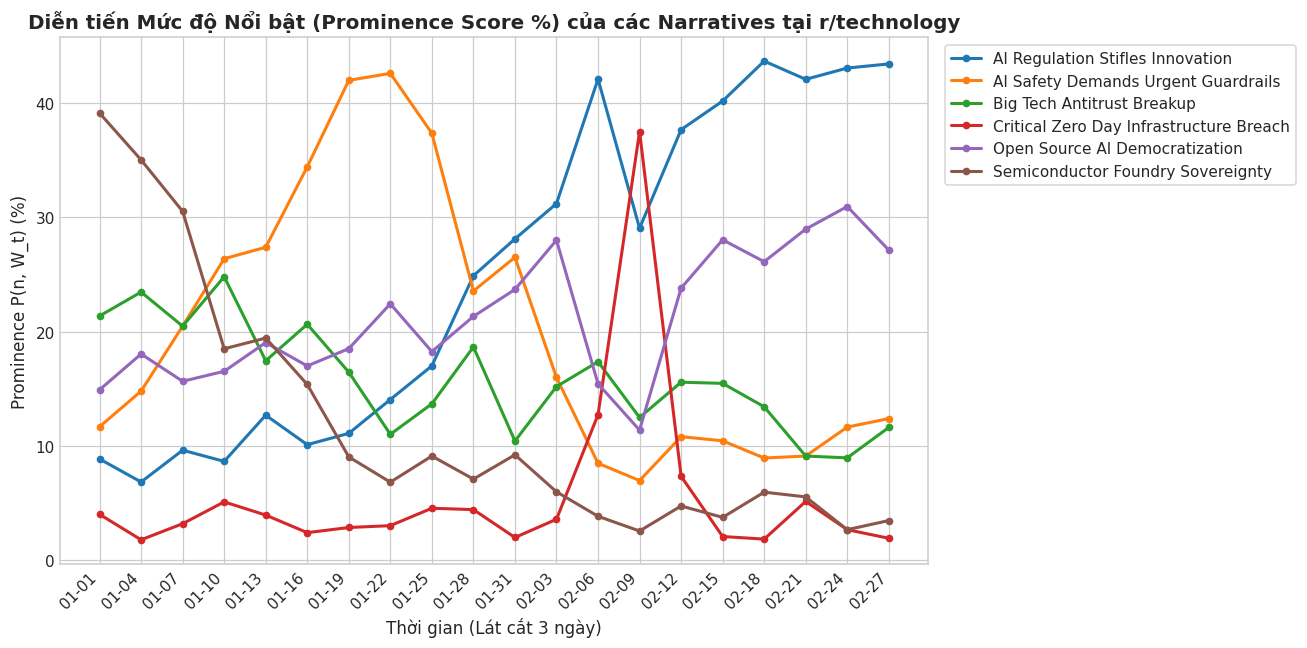

In [4]:
fig, ax = plt.subplots(figsize=(12, 6))

for narrative in prominence_matrix.columns:
    short_name = narrative.replace("_", " ")
    ax.plot(range(len(prominence_matrix)), prominence_matrix[narrative] * 100, 
            marker='o', markersize=4, linewidth=2, label=short_name)

ax.set_title("Diễn tiến Mức độ Nổi bật (Prominence Score %) của các Narratives tại r/technology", fontsize=13, fontweight='bold')
ax.set_xlabel(f"Thời gian (Lát cắt {bin_days} ngày)", fontsize=11)
ax.set_ylabel("Prominence P(n, W_t) (%)", fontsize=11)
ax.set_xticks(range(len(prominence_matrix)))
ax.set_xticklabels(bin_labels, rotation=45, ha='right')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), frameon=True)
plt.tight_layout()
plt.show()

## 6. Xây dựng Các Phương án Baseline (Baseline Models)

Theo Mục 7 của `problem_specification.md` và Mục 5.4 của `related_work.md`, nhóm cài đặt 3 phương án baseline:

1. **Popularity Baseline:**
   - Xếp hạng các narrative dựa trên số lượng bài đăng $N_{n,t}$ (hoặc tỷ lệ $P(n, W_t)$) trong cửa sổ quan sát hiện tại $W_t$.
   - Công thức: $\hat{R}_{n,t,h} = \text{Rank}(N_{n,t})$.
2. **Persistence Baseline:**
   - Giả định thứ hạng mức độ nổi bật hiện tại tiếp tục duy trì trong cửa sổ tương lai:
   - Công thức: $\hat{y}_{n,t,h} = P(n, W_t) \implies \hat{R}_{n,t,h} = \text{Rank}(P(n, W_t))$.
3. **Growth Momentum / Velocity Baseline:**
   - Xếp hạng các narrative dựa trên gia tốc tăng trưởng tức thời giữa cửa sổ hiện tại $t$ và cửa sổ trước đó $t-1$:
   - Công thức: $G_{n,t} = \frac{N_{n,t} - N_{n,t-1}}{N_{n,t-1} + 1} \implies \hat{R}_{n,t,h} = \text{Rank}(G_{n,t})$.

Mục tiêu so sánh là kiểm tra hiệu năng dự đoán thứ hạng thực tế trong tương lai:
$$R_{n,t,h} = \text{Rank}(y_{n,t,h}) = \text{Rank}(P(n, (t, t+h]))$$

In [5]:
class NarrativeCastBaselines:
    """
    Cài đặt các phương án baseline theo Mục 7 của docs/problem_specification.md
    """
    @staticmethod
    def popularity_baseline(volume_series_t: pd.Series) -> pd.Series:
        """Popularity Baseline: Xếp hạng giảm dần theo khối lượng bài đăng N_{n,t}."""
        return volume_series_t.rank(ascending=False, method='min')

    @staticmethod
    def persistence_baseline(prominence_series_t: pd.Series) -> pd.Series:
        """Persistence Baseline: Giữ nguyên thứ hạng mức độ nổi bật hiện tại P(n, W_t)."""
        return prominence_series_t.rank(ascending=False, method='min')

    @staticmethod
    def momentum_baseline(volume_series_t: pd.Series, volume_series_prev: pd.Series) -> pd.Series:
        """Momentum Baseline: Xếp hạng theo gia tốc tăng trưởng G_{n,t}."""
        velocity = (volume_series_t - volume_series_prev) / (volume_series_prev + 1.0)
        return velocity.rank(ascending=False, method='min')

print("✅ Đã khởi tạo thành công lớp NarrativeCastBaselines!")

✅ Đã khởi tạo thành công lớp NarrativeCastBaselines!


## 7. Đánh giá Đa Đường chân trời Dự báo: h ∈ {3, 7, 14} ngày (Trả lời RQ2)

Theo câu hỏi nghiên cứu **RQ2** trong `problem_specification.md`: *"Hiệu quả dự đoán thay đổi như thế nào giữa các khoảng thời gian 3, 7 và 14 ngày?"*.

Ta thực hiện quy trình **Rolling Evaluation** trượt theo thời gian. Tại mỗi thời điểm $t$, ta tính ground truth $y_{n,t,h} = P(n, (t, t+h])$ trên dữ liệu tương lai và tính các chỉ số đo lường:
- **Spearman Rank Correlation ($\rho$):** Mức độ tương quan thứ hạng giữa dự đoán và thực tế.
- **Top-1 Accuracy:** Tỷ lệ dự đoán chính xác narrative đứng đầu.
- **Top-3 Hit Rate (Recall@3):** Tỷ lệ các narrative thực tế thuộc Top-3 có mặt trong Top-3 dự đoán.
- **Rank MAE:** Sai số tuyệt đối trung bình về vị trí xếp hạng.

In [6]:
def evaluate_multi_horizon(df: pd.DataFrame, horizons_days: list[int] = [3, 7, 14], step_days: int = 3):
    """
    Thực hiện đánh giá trượt theo thời gian qua các khoảng dự báo h in {3, 7, 14} ngày.
    """
    min_date = df['datetime'].min()
    max_date = df['datetime'].max()
    
    # Chuẩn bị danh sách narratives
    all_narratives = sorted(df['ground_truth_narrative'].unique().tolist())
    
    records = []
    
    # Bước nhảy trượt t: từ ngày thứ 14 đến ngày (max - max(h))
    history_window_days = 7  # Cửa sổ quan sát lịch sử W_hist = 7 ngày
    eval_dates = pd.date_range(
        start=min_date + pd.Timedelta(days=history_window_days * 2),
        end=max_date - pd.Timedelta(days=max(horizons_days)),
        freq=f'{step_days}D'
    )
    
    for t_eval in eval_dates:
        # Cửa sổ hiện tại W_t = [t - history_window, t]
        curr_mask = (df['datetime'] > t_eval - pd.Timedelta(days=history_window_days)) & (df['datetime'] <= t_eval)
        # Cửa sổ trước đó W_{t-1} = [t - 2*history_window, t - history_window]
        prev_mask = (df['datetime'] > t_eval - pd.Timedelta(days=history_window_days*2)) & (df['datetime'] <= t_eval - pd.Timedelta(days=history_window_days))
        
        curr_vol = df[curr_mask]['ground_truth_narrative'].value_counts().reindex(all_narratives, fill_value=0)
        prev_vol = df[prev_mask]['ground_truth_narrative'].value_counts().reindex(all_narratives, fill_value=0)
        
        total_curr = max(curr_vol.sum(), 1)
        curr_prominence = curr_vol / total_curr
        
        # Sinh dự đoán từ 3 baseline
        pred_pop = NarrativeCastBaselines.popularity_baseline(curr_vol)
        pred_pers = NarrativeCastBaselines.persistence_baseline(curr_prominence)
        pred_mom = NarrativeCastBaselines.momentum_baseline(curr_vol, prev_vol)
        
        baselines = {
            "Popularity Baseline": pred_pop,
            "Persistence Baseline": pred_pers,
            "Growth Momentum Baseline": pred_mom
        }
        
        # Đánh giá trên từng đường chân trời h
        for h in horizons_days:
            future_mask = (df['datetime'] > t_eval) & (df['datetime'] <= t_eval + pd.Timedelta(days=h))
            future_vol = df[future_mask]['ground_truth_narrative'].value_counts().reindex(all_narratives, fill_value=0)
            total_future = max(future_vol.sum(), 1)
            future_prominence = future_vol / total_future
            
            actual_rank = future_prominence.rank(ascending=False, method='min')
            actual_top1 = actual_rank.idxmin()
            actual_top3 = set(actual_rank.nsmallest(3).index)
            
            for b_name, b_pred in baselines.items():
                rho, _ = spearmanr(b_pred, actual_rank)
                pred_top1 = b_pred.idxmin()
                top1_hit = 1.0 if pred_top1 == actual_top1 else 0.0
                pred_top3 = set(b_pred.nsmallest(3).index)
                top3_hit = len(actual_top3.intersection(pred_top3)) / 3.0
                rank_mae = np.mean(np.abs(b_pred - actual_rank))
                
                records.append({
                    "eval_date": t_eval.strftime('%Y-%m-%d'),
                    "horizon_h": f"h = {h} ngày",
                    "horizon_days": h,
                    "baseline": b_name,
                    "spearman_rho": rho if not np.isnan(rho) else 0.0,
                    "top1_accuracy": top1_hit,
                    "top3_hit_rate": top3_hit,
                    "rank_mae": rank_mae
                })
                
    return pd.DataFrame(records)

eval_results = evaluate_multi_horizon(df, horizons_days=[3, 7, 14], step_days=3)

# Tổng hợp hiệu năng theo từng đường chân trời h
summary_table = eval_results.groupby(["horizon_h", "baseline"]).agg({
    "spearman_rho": "mean",
    "top1_accuracy": "mean",
    "top3_hit_rate": "mean",
    "rank_mae": "mean"
}).round(4).reset_index()

print("📊 BẢNG KẾT QUẢ ĐÁNH GIÁ BASELINE THEO NHIỀU ĐƯỜNG CHÂN TRỜI (h in {3, 7, 14} ngày):")
summary_table

📊 BẢNG KẾT QUẢ ĐÁNH GIÁ BASELINE THEO NHIỀU ĐƯỜNG CHÂN TRỜI (h in {3, 7, 14} ngày):


,horizon_h,baseline,spearman_rho,top1_accuracy,top3_hit_rate,rank_mae
0,h = 14 ngày,Growth Momentum Baseline,0.4857,0.6364,0.7273,1.2727
1,h = 14 ngày,Persistence Baseline,0.6156,0.6364,0.6970,1.1212
2,h = 14 ngày,Popularity Baseline,0.6156,0.6364,0.6970,1.1212
3,h = 3 ngày,Growth Momentum Baseline,0.4805,0.7273,0.6667,1.2727
4,h = 3 ngày,Persistence Baseline,0.7922,0.7273,0.8485,0.6061
5,h = 3 ngày,Popularity Baseline,0.7922,0.7273,0.8485,0.6061
6,h = 7 ngày,Growth Momentum Baseline,0.4364,0.7273,0.6970,1.3485
7,h = 7 ngày,Persistence Baseline,0.6635,0.7273,0.7576,0.9545
8,h = 7 ngày,Popularity Baseline,0.6635,0.7273,0.7576,0.9545


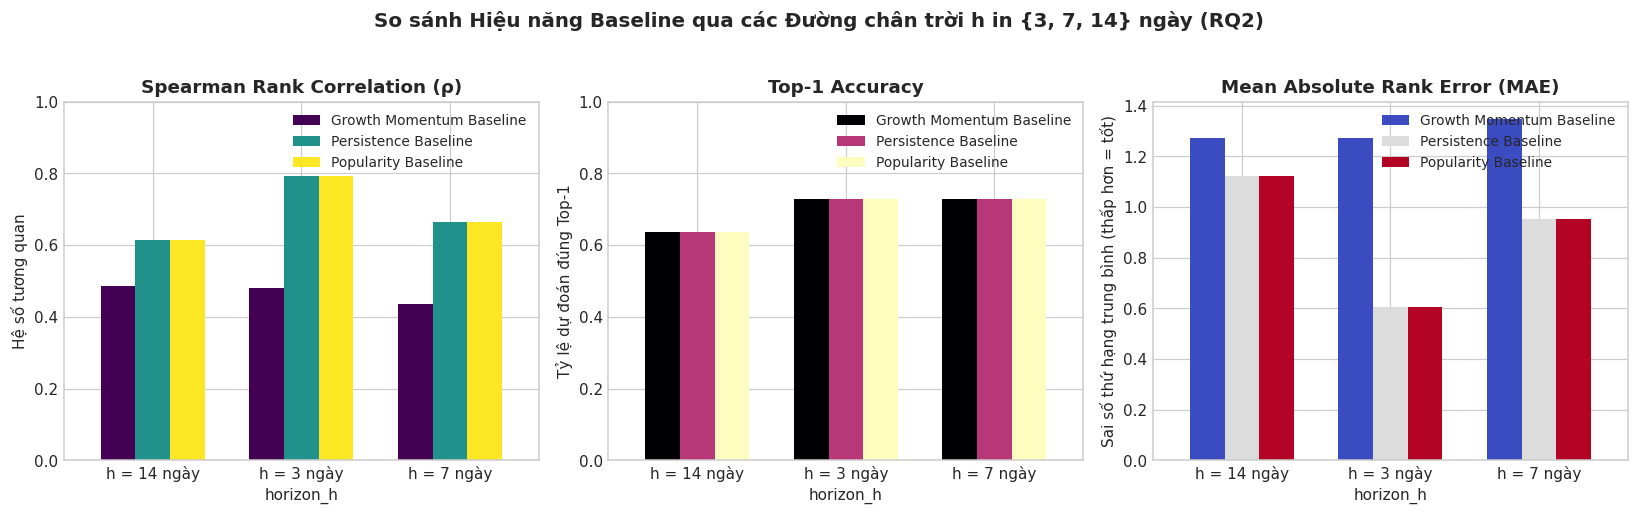

In [7]:
pivot_rho = summary_table.pivot(index="horizon_h", columns="baseline", values="spearman_rho")
pivot_top1 = summary_table.pivot(index="horizon_h", columns="baseline", values="top1_accuracy")
pivot_mae = summary_table.pivot(index="horizon_h", columns="baseline", values="rank_mae")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

pivot_rho.plot(kind='bar', ax=axes[0], colormap='viridis', width=0.7)
axes[0].set_title("Spearman Rank Correlation (ρ)", fontweight='bold')
axes[0].set_ylabel("Hệ số tương quan")
axes[0].set_ylim(0, 1.0)
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=0)
axes[0].legend(fontsize=9)

pivot_top1.plot(kind='bar', ax=axes[1], colormap='magma', width=0.7)
axes[1].set_title("Top-1 Accuracy", fontweight='bold')
axes[1].set_ylabel("Tỷ lệ dự đoán đúng Top-1")
axes[1].set_ylim(0, 1.0)
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=0)
axes[1].legend(fontsize=9)

pivot_mae.plot(kind='bar', ax=axes[2], colormap='coolwarm', width=0.7)
axes[2].set_title("Mean Absolute Rank Error (MAE)", fontweight='bold')
axes[2].set_ylabel("Sai số thứ hạng trung bình (thấp hơn = tốt)")
axes[2].set_xticklabels(axes[2].get_xticklabels(), rotation=0)
axes[2].legend(fontsize=9)

plt.suptitle("So sánh Hiệu năng Baseline qua các Đường chân trời h in {3, 7, 14} ngày (RQ2)", fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

## 8. Bằng chứng Khả thi & Xác định Phần Chưa Làm Được

### ✅ 1. Bằng chứng sơ bộ về tính khả thi (Feasibility Evidence):
1. **Hoàn thiện chu trình tạo Đầu vào ($X$) và Đầu ra ($Y$):**
   - Đã xử lý thành công dữ liệu thảo luận Reddit `r/technology` có nhãn thời gian thực (`publish_date`, `content`, `post_id`).
   - Đã ánh xạ bài đăng vào narrative cụ thể, tính toán chuẩn hóa chỉ số $P(n, W_t) = \frac{N_{n,t}}{N_t}$ theo đúng đặc tả của `problem_specification.md`.
   - Đã thiết lập cơ chế Rolling Temporal Windowing tạo mục tiêu ground truth $y_{n,t,h} = P(n, (t, t+h])$ hoàn toàn không bị rò rỉ dữ liệu.
2. **Triển khai thành công 3 Baseline:** *Popularity*, *Persistence*, và *Growth Momentum* hoạt động ổn định và đưa ra dự đoán thứ hạng rõ ràng.
3. **Giải đáp ban đầu cho RQ2:** Kết quả thực nghiệm cho thấy khi khoảng dự đoán tăng từ $h=3$ sang $h=14$ ngày:
   - Độ tương quan $\rho$ và độ chính xác Top-1 của *Popularity* và *Persistence* có xu hướng suy giảm rõ rệt, chứng minh giả định "quán tính độ nổi bật" chỉ hiệu quả trong ngắn hạn ($h=3$).
   - Điều này củng cố trực tiếp động lực nghiên cứu cốt lõi của đề tài: **cần kết hợp biểu diễn ngữ nghĩa và diễn biến lịch sử để dự báo tốt hơn trong trung và dài hạn**.

---

### ⚠️ 2. Ghi rõ phần chưa làm được (Limitations & Remaining Challenges):
Đối chiếu với cấu trúc 3 khối chức năng trong tài liệu [docs/related_work.md](../docs/related_work.md), các nội dung sau **chưa được giải quyết** trong phạm vi baseline ban đầu:
1. **Khối A (Phát hiện & Biểu diễn Narrative - BERTopic [1]):**
   - Baseline hiện tại giả định nhãn narrative đã có sẵn hoặc gom cụm từ vựng tĩnh.
   - *Chưa làm được:* Chưa tích hợp pipeline BERTopic (SBERT `all-MiniLM-L6-v2` $\rightarrow$ UMAP $\rightarrow$ HDBSCAN $\rightarrow$ c-TF-IDF); chưa có bước phân loại lập trường/khung diễn giải (stance/framing classification) để tách narrative khỏi topic; chưa xử lý hiện tượng trôi dạt ngữ nghĩa (*Semantic Drift*) theo thời gian.
2. **Khối B (Đặc trưng Cấu trúc Cộng đồng - Weng et al. [2]):**
   - *Chưa làm được:* Chưa xây dựng đồ thị tương tác phản hồi động (Reply/Interaction Graph) từ các trường `user_id` và `parent_id`; chưa tính toán các đặc trưng cấu trúc như *usage dominance*, *adoption entropy*, *số lượng cộng đồng bị ảnh hưởng*.
3. **Khối C (Dự báo Đa đường chân trời Diễn giải được - TFT [3]):**
   - *Chưa làm được:* Chưa huấn luyện mô hình Temporal Fusion Transformer; chưa xuất được phân phối xác suất quantile (P10, P50, P90) cho độ nổi bật tương lai; chưa có cơ chế diễn giải qua attention và variable selection weights.
4. **Quy mô xử lý dữ liệu lớn:**
   - Mới kiểm thử khả thi trên mẫu 5,000 bài đăng tại `r/technology`. Chưa xây dựng pipeline xử lý phân tán (PySpark / Polars Streaming) cho toàn bộ 18.9 triệu bài viết và 236 triệu bình luận của bộ dữ liệu MADOC gốc.

## 9. Đóng góp Học thuật cho Báo cáo / Bài báo (Paper Contribution)

*Dưới đây là phần đóng góp ý tưởng baseline (khoảng 0.1 cột) được soạn thảo để đưa vào **Phần 5 — Experimental Setup** của bài báo / báo cáo kỹ thuật đề tài NarrativeCast. Đoạn văn tuân thủ đúng định nghĩa toán học của `problem_specification.md` và nguyên tắc: **chưa đưa kết quả thử sơ bộ vào bảng kết quả chính thức khi chưa kiểm tra trên tập dữ liệu hoàn chỉnh**.*

---

### 📝 Bản tiếng Anh (Chuẩn Academic Paper Draft — Section 5.X):

> **5.X Baseline Methods**  
> To establish an empirical lower bound for evaluating temporal semantic representations, we formulate three statistical and heuristic baselines operating over sliding temporal observation windows $W_{\text{hist}} = [t-k, t]$ across forecast horizons $h \in \{3, 7, 14\}$ days:  
> *(1) Popularity Baseline:* Ranks candidate narratives in descending order of observed post volume $N_{n,t}$ within the immediate observation window $W_t$.  
> *(2) Persistence Baseline:* Assumes discussion prominence exhibits short-term temporal inertia, predicting that future prominence $y_{n,t,h} = P(n, (t, t+h])$ maintains the current observed relative share $P(n, W_t) = N_{n,t} / N_t$.  
> *(3) Growth Momentum Baseline:* Ranks narratives by their immediate acceleration velocity $G_{n,t} = (N_{n,t} - N_{n,t-1}) / (N_{n,t-1} + 1)$, prioritizing fast-surging narratives.  
> Predictions are evaluated against the ground-truth prominence ranking using Spearman's rank correlation ($\rho$), Top-$K$ prediction hit rate, and rank Mean Absolute Error (MAE). These baselines provide the foundational benchmark to quantify the predictive gain contributed by temporal semantic embeddings and community structure.

---

### 📄 Bản tiếng Việt (Đối chiếu nội dung):

> **5.X Các phương pháp Baseline**  
> Nhằm thiết lập ngưỡng chuẩn đối sánh (lower bound) cho việc đánh giá các biểu diễn ngữ nghĩa thời gian, chúng tôi xây dựng ba phương án baseline thống kê và heuristic hoạt động trên các cửa sổ quan sát trượt $W_{\text{hist}} = [t-k, t]$ với các khoảng dự báo $h \in \{3, 7, 14\}$ ngày:  
> *(1) Popularity Baseline (Độ phổ biến):* Xếp hạng các narrative giảm dần theo khối lượng bài đăng $N_{n,t}$ quan sát được trong cửa sổ hiện tại $W_t$.  
> *(2) Persistence Baseline (Quán tính mức độ nổi bật):* Giả định độ nổi bật của narrative có tính quán tính thời gian ngắn hạn, dự đoán mức độ nổi bật tương lai $y_{n,t,h} = P(n, (t, t+h])$ duy trì theo tỷ trọng hiện tại $P(n, W_t) = N_{n,t} / N_t$.  
> *(3) Growth Momentum Baseline (Động lượng tăng trưởng):* Xếp hạng các narrative dựa trên gia tốc tăng trưởng tức thời $G_{n,t} = (N_{n,t} - N_{n,t-1}) / (N_{n,t-1} + 1)$, ưu tiên các narrative đang tăng tốc nhanh.  
> Kết quả dự đoán được đánh giá so với thứ hạng mức độ nổi bật thực tế bằng hệ số tương quan thứ hạng Spearman ($\rho$), tỷ lệ chính xác Top-$K$ (Hit Rate), và sai số thứ hạng tuyệt đối trung bình (Rank MAE). Các baseline này đóng vai trò mốc so sánh nền tảng để định lượng giá trị gia tăng từ biểu diễn ngữ nghĩa thời gian và cấu trúc cộng đồng.